# Model Comparison

## Libraries

In [1]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, roc_curve
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import time # Training time of each model

## Data Loading And Configuration

In [2]:
full_df = pd.read_csv("./dataset.csv")
full_df["date"] = pd.to_datetime(full_df['date'], format='%Y-%m-%d')

np.random.seed(42)

In [3]:
FEATURES = [c for c in full_df.columns if c not in ['date', 'longitude', 'latitude', 'fire']] # Coordinates and date are not used as variables
CATEGORICAL = ["structure_type", "fuel_model", "biogeographic_region", "development_stage", "stand_distribution"]

EMBARGO = pd.Timedelta(days=90) # Same as the longest rolling window, avoids leakage between train and test
TEST_YEARS = range(2015, full_df['date'].dt.year.max() + 1)

K = 5 # Number of spatial folds
BLOCK_SIZE = 0.3 # Size (in degrees) of each spatial block

# Colors used in every plot
TEMPORAL_COLOR = "#2a78d6"
SPATIAL_COLOR = "#eb6834"

## Validation Splits
---
Two different tests are used, each one answers a different question:
- **Temporal**: can the model predict fires of a future year? Each year from 2015 is tested with a model trained only on previous data (with a 90 days embargo).
- **Spatial**: can the model predict fires in zones it has never seen? The map is divided in blocks and the blocks are distributed in K folds.

In [4]:
# Mask generation for temporal evaluation
temporal_splits = [
    (year,
     full_df['date'] <= pd.Timestamp(f'{year}-01-01') - EMBARGO,
     full_df['date'].dt.year == year)
    for year in TEST_YEARS
]

# Lon and lat division in blocks
block_lon = (full_df['longitude'] // BLOCK_SIZE).astype(int)
block_lat = (full_df['latitude'] // BLOCK_SIZE).astype(int)

# Individual block ID for each entry
block_id = block_lon.astype(str) + '_' + block_lat.astype(str)

blocks = np.array(block_id.unique()) # Unique blocks

np.random.shuffle(blocks)

# Replaces blocks ID for fold number
fold = block_id.map(dict(zip(blocks, np.arange(len(blocks)) % K)))

# Mask generation for spatial evaluation
spatial_splits = [(k, fold != k, fold == k) for k in range(K)]

## Evaluation Function
---
For each split the model is trained from scratch and three metrics are computed:
- **ROC-AUC**: main metric, independent of the decision threshold.
- **PR-AUC**: focused on the positive class (fires), more demanding than ROC-AUC.
- **F1**: using the default 0.5 threshold, so it also depends on how each model handles the class imbalance.

The predictions of every split are also saved to draw the ROC curves later.

In [5]:
def evaluate(model, splits):
    rows = []
    y_true, y_proba = [], []

    for split, train_idx, test_idx in splits:
        X_train, y_train = full_df.loc[train_idx, FEATURES], full_df.loc[train_idx, 'fire']
        X_test, y_test = full_df.loc[test_idx, FEATURES], full_df.loc[test_idx, 'fire']

        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_time = time.perf_counter() - start

        proba = model.predict_proba(X_test)[:, 1]

        rows.append({
            'split': split,
            'roc_auc': roc_auc_score(y_test, proba),
            'pr_auc': average_precision_score(y_test, proba),
            'f1': f1_score(y_test, proba >= 0.5),
            'fit_time': fit_time,
        })

        y_true.append(y_test.values)
        y_proba.append(proba)

    return pd.DataFrame(rows), np.concatenate(y_true), np.concatenate(y_proba)

## Models
---
Several families are compared, from the simplest to the most complex:
- **Baseline**: always predicts the class proportion, any useful model must beat it.
- **Linear / probabilistic**: Logistic Regression and Naive Bayes.
- **Instance based**: K-Nearest Neighbors.
- **Single tree**: Decision Tree.
- **Bagging**: Random Forest and Extra Trees.
- **Boosting**: HistGradientBoosting, XGBoost, LightGBM and CatBoost.
- **Neural network**: Multilayer Perceptron.

Tree based models work directly with the raw data (they support NaN and don't need scaling). The rest need the missing values imputed, the categorical codes one-hot encoded and the numeric variables standardized.

In [6]:
NEG_POS_RATIO = (full_df['fire'] == 0).sum() / (full_df['fire'] == 1).sum() # Used to balance the boosting models

# Preprocessing for the non tree models: impute + one-hot for categorical, impute + scale for the rest
def scaled_preprocess():
    return ColumnTransformer(
        [('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), CATEGORICAL)],
        remainder=make_pipeline(SimpleImputer(strategy='median'), StandardScaler()),
        sparse_threshold=0, # Dense output, needed by Naive Bayes
    )

In [7]:
MODELS = {
    # Baseline
    'Dummy': DummyClassifier(strategy='prior'),

    # Linear / probabilistic
    'LogisticRegression': make_pipeline(
        scaled_preprocess(),
        LogisticRegression(class_weight='balanced', max_iter=2000),
    ),
    'NaiveBayes': make_pipeline(
        scaled_preprocess(),
        GaussianNB(),
    ),

    # Instance based
    'KNN': make_pipeline(
        scaled_preprocess(),
        KNeighborsClassifier(n_neighbors=50, weights='distance', n_jobs=-1),
    ),

    # Single tree
    'DecisionTree': DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=20,
        class_weight='balanced',
        random_state=42,
    ),

    # Bagging
    'RandomForest': RandomForestClassifier(
        n_estimators=500,
        max_features='sqrt',
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
    ),
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=500,
        max_features='sqrt',
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
    ),

    # Boosting
    'HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=500,
        learning_rate=0.05,
        max_leaf_nodes=63,
        class_weight='balanced',
        random_state=42,
    ),
    'XGBoost': XGBClassifier(
        n_estimators=1000,
        learning_rate=0.02,
        max_depth=10,
        subsample=0.8,
        colsample_bytree=0.7,
        scale_pos_weight=NEG_POS_RATIO,
        random_state=42,
        n_jobs=-1,
    ),
    'LightGBM': LGBMClassifier( # Trees grow by leaves instead of by levels
        n_estimators=1000,
        learning_rate=0.02,
        num_leaves=63,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.7,
        scale_pos_weight=NEG_POS_RATIO,
        random_state=42,
        n_jobs=-1,
        verbose=-1,
    ),
    'CatBoost': CatBoostClassifier( # Symmetric trees, usually overfits less
        iterations=1000,
        learning_rate=0.05,
        depth=8,
        auto_class_weights='Balanced',
        random_seed=42,
        thread_count=-1,
        allow_writing_files=False, # Avoids the catboost_info folder
        verbose=0,
    ),

    # Neural network
    'MLP': make_pipeline(
        scaled_preprocess(),
        MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=300, random_state=42),
    ),
}

In [8]:
# Family of each model, used to compare the best model of every family
MODEL_FAMILY = {
    'Dummy': 'Baseline',
    'LogisticRegression': 'Linear',
    'NaiveBayes': 'Probabilistic',
    'KNN': 'Instance based',
    'DecisionTree': 'Single tree',
    'RandomForest': 'Bagging',
    'ExtraTrees': 'Bagging',
    'HistGradientBoosting': 'Boosting',
    'XGBoost': 'Boosting',
    'LightGBM': 'Boosting',
    'CatBoost': 'Boosting',
    'MLP': 'Neural network',
}

## Training And Evaluation

In [9]:
results = [] # One row per model, test and split
predictions = {} # Predictions of every split joined, used for the ROC curves

for name, model in MODELS.items():
    for scheme, splits in [('temporal', temporal_splits), ('spatial', spatial_splits)]:
        metrics, y_true, y_proba = evaluate(model, splits)
        metrics['model'] = name
        metrics['scheme'] = scheme

        results.append(metrics)
        predictions[(name, scheme)] = (y_true, y_proba)

    model_results = pd.concat(results[-2:])
    print(f"{name:<22} | AUC temporal={model_results.loc[model_results['scheme'] == 'temporal', 'roc_auc'].mean():.3f}"
          f" | AUC spatial={model_results.loc[model_results['scheme'] == 'spatial', 'roc_auc'].mean():.3f}"
          f" | fit time={model_results['fit_time'].mean():.1f}s")

results = pd.concat(results, ignore_index=True)

Dummy                  | AUC temporal=0.500 | AUC spatial=0.500 | fit time=0.0s


LogisticRegression     | AUC temporal=0.715 | AUC spatial=0.711 | fit time=1.5s


NaiveBayes             | AUC temporal=0.659 | AUC spatial=0.653 | fit time=0.4s


KNN                    | AUC temporal=0.735 | AUC spatial=0.730 | fit time=0.3s


DecisionTree           | AUC temporal=0.721 | AUC spatial=0.696 | fit time=1.5s


RandomForest           | AUC temporal=0.773 | AUC spatial=0.765 | fit time=21.4s


... (2 outputs left out)

XGBoost                | AUC temporal=0.796 | AUC spatial=0.764 | fit time=23.6s


LightGBM               | AUC temporal=0.797 | AUC spatial=0.767 | fit time=4.8s


CatBoost               | AUC temporal=0.795 | AUC spatial=0.766 | fit time=31.0s


MLP                    | AUC temporal=0.764 | AUC spatial=0.757 | fit time=11.7s


## Results Summary
---
The models are ranked by a score that combines both tests: the mean ROC-AUC penalized by its instability between years / zones.

In [10]:
def scheme_stat(metric, scheme, stat):
    return results[results['scheme'] == scheme].groupby('model')[metric].agg(stat)

summary = pd.DataFrame({
    'temporal_auc': scheme_stat('roc_auc', 'temporal', 'mean'),
    'temporal_std': scheme_stat('roc_auc', 'temporal', 'std'),
    'spatial_auc': scheme_stat('roc_auc', 'spatial', 'mean'),
    'spatial_std': scheme_stat('roc_auc', 'spatial', 'std'),
    'temporal_pr_auc': scheme_stat('pr_auc', 'temporal', 'mean'),
    'spatial_pr_auc': scheme_stat('pr_auc', 'spatial', 'mean'),
    'temporal_f1': scheme_stat('f1', 'temporal', 'mean'),
    'spatial_f1': scheme_stat('f1', 'spatial', 'mean'),
    'fit_time': results.groupby('model')['fit_time'].mean(),
})

# Mean of both tests penalized by its instability between years / zones
summary['score'] = (summary['temporal_auc'] + summary['spatial_auc']) / 2 - (summary['temporal_std'] + summary['spatial_std']) / 2
summary = summary.sort_values('score', ascending=False)

ORDER = summary.index.tolist() # Same model order in every plot
MODELS_NO_BASELINE = [m for m in ORDER if m != 'Dummy'] # The baseline is removed when it only adds noise to the plot

summary.round(3)

,temporal_auc,temporal_std,spatial_auc,spatial_std,temporal_pr_auc,spatial_pr_auc,temporal_f1,spatial_f1,fit_time,score
model,,,,,,,,,,
LightGBM,0.797,0.025,0.767,0.009,0.651,0.616,0.612,0.583,4.779,0.765
XGBoost,0.796,0.024,0.764,0.008,0.650,0.615,0.596,0.550,23.637,0.764
CatBoost,0.795,0.025,0.766,0.009,0.648,0.615,0.610,0.582,31.049,0.763
HistGradientBoosting,0.791,0.026,0.761,0.008,0.641,0.609,0.604,0.579,10.318,0.759
RandomForest,0.773,0.027,0.765,0.010,0.616,0.612,0.560,0.556,21.430,0.750
ExtraTrees,0.764,0.027,0.760,0.009,0.601,0.605,0.507,0.502,9.377,0.744
MLP,0.764,0.027,0.757,0.010,0.599,0.602,0.509,0.500,11.735,0.742
KNN,0.735,0.026,0.730,0.014,0.562,0.564,0.427,0.409,0.305,0.712
LogisticRegression,0.715,0.028,0.711,0.015,0.526,0.536,0.543,0.552,1.549,0.692


#### ROC-AUC In Both Tests
The x axis starts at 0.5, which is the AUC of a random classifier. Error bars show the standard deviation between years / folds.

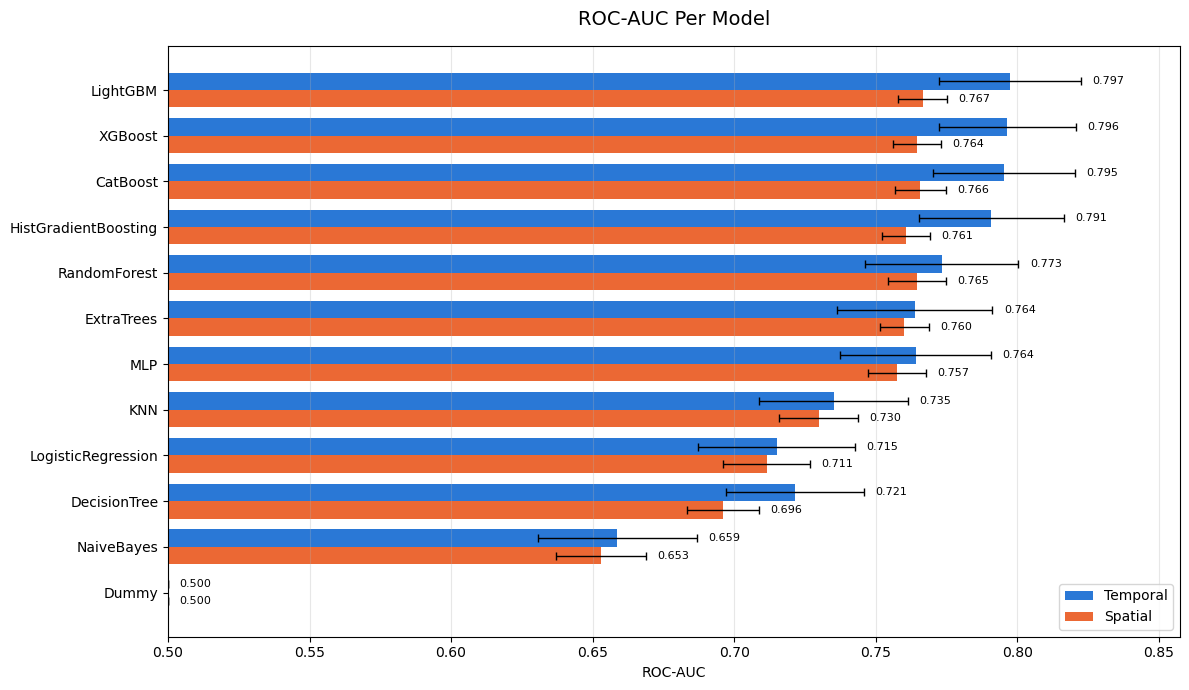

In [11]:
fig, ax = plt.subplots(figsize=(12, 7))

y = np.arange(len(ORDER))
height = 0.38

ax.barh(y - height / 2, summary['temporal_auc'] - 0.5, height, left=0.5, xerr=summary['temporal_std'],
        color=TEMPORAL_COLOR, label='Temporal', capsize=3, error_kw={'lw': 1})
ax.barh(y + height / 2, summary['spatial_auc'] - 0.5, height, left=0.5, xerr=summary['spatial_std'],
        color=SPATIAL_COLOR, label='Spatial', capsize=3, error_kw={'lw': 1})

# Value of each bar next to its error bar
for i, model in enumerate(ORDER):
    ax.text(summary.loc[model, 'temporal_auc'] + summary.loc[model, 'temporal_std'] + 0.004, i - height / 2,
            f"{summary.loc[model, 'temporal_auc']:.3f}", va='center', fontsize=8)
    ax.text(summary.loc[model, 'spatial_auc'] + summary.loc[model, 'spatial_std'] + 0.004, i + height / 2,
            f"{summary.loc[model, 'spatial_auc']:.3f}", va='center', fontsize=8)

ax.set_yticks(y, ORDER)
ax.invert_yaxis() # Best model on top
ax.set_xlim(0.5, (summary[['temporal_auc', 'spatial_auc']].max().max() + 0.06))
ax.set_xlabel("ROC-AUC")
ax.set_title("ROC-AUC Per Model", fontsize=14, pad=15)
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

#### ROC-AUC Distribution
Each box contains the AUC of every year (temporal) or fold (spatial). Narrow boxes mean a stable model.

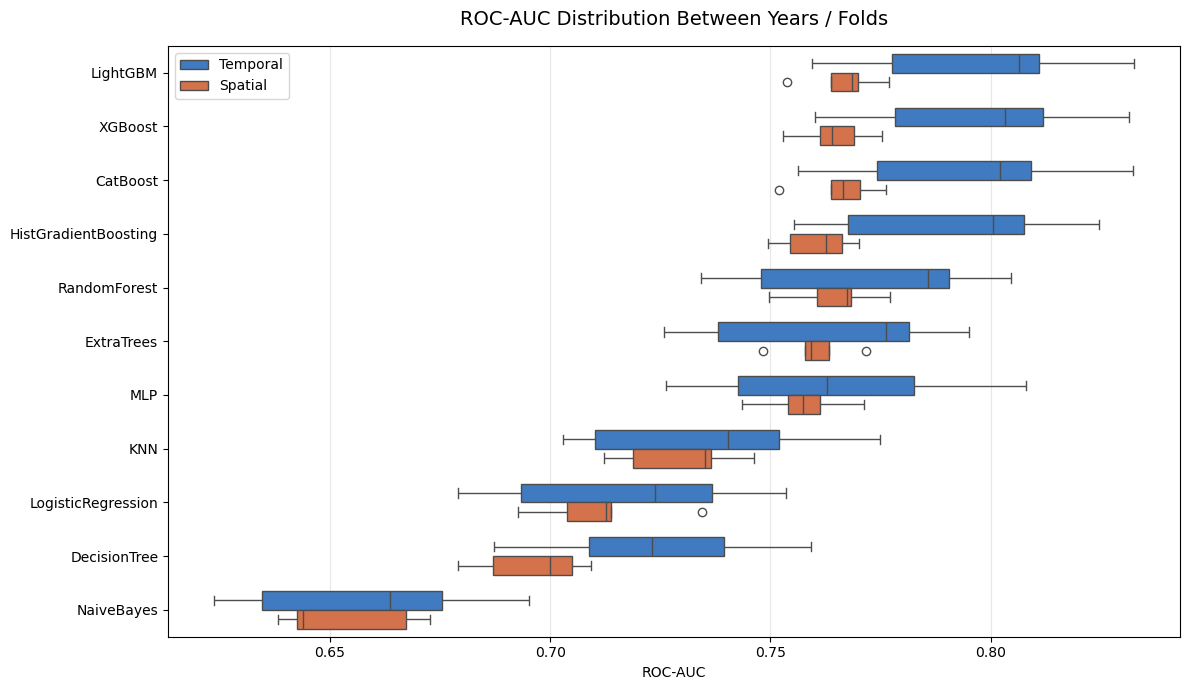

In [12]:
fig, ax = plt.subplots(figsize=(12, 7))

sns.boxplot(
    data=results[results['model'] != 'Dummy'],
    x='roc_auc',
    y='model',
    hue='scheme',
    order=MODELS_NO_BASELINE,
    hue_order=['temporal', 'spatial'],
    palette=[TEMPORAL_COLOR, SPATIAL_COLOR],
    width=0.7,
    ax=ax,
)

ax.set_xlabel("ROC-AUC")
ax.set_ylabel("")
ax.set_title("ROC-AUC Distribution Between Years / Folds", fontsize=14, pad=15)
ax.grid(axis='x', alpha=0.3)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Temporal', 'Spatial'])

plt.tight_layout()
plt.show()

#### ROC-AUC Per Year And Per Fold
Shows if the ranking of the models is consistent or if it changes depending on the year / zone.

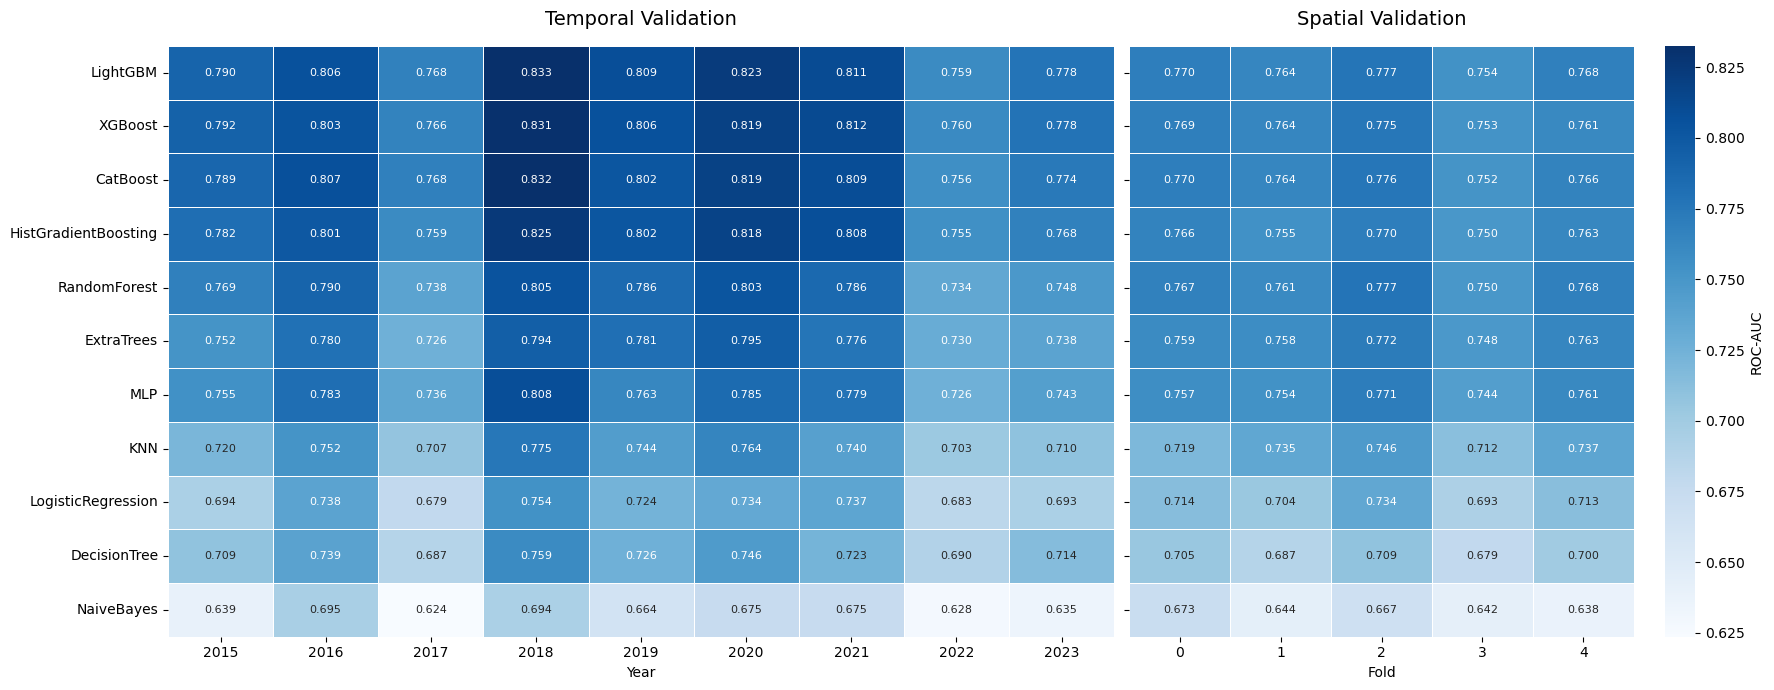

In [13]:
temporal_matrix = results[results['scheme'] == 'temporal'].pivot(index='model', columns='split', values='roc_auc').loc[MODELS_NO_BASELINE]
spatial_matrix = results[results['scheme'] == 'spatial'].pivot(index='model', columns='split', values='roc_auc').loc[MODELS_NO_BASELINE]

# Same color scale in both heatmaps so they can be compared
vmin = min(temporal_matrix.min().min(), spatial_matrix.min().min())
vmax = max(temporal_matrix.max().max(), spatial_matrix.max().max())

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [len(TEST_YEARS), K + 1]}, sharey=True)

sns.heatmap(temporal_matrix, annot=True, fmt=".3f", cmap="Blues", vmin=vmin, vmax=vmax,
            linewidths=0.5, annot_kws={"size": 8}, cbar=False, ax=axes[0])
axes[0].set_xlabel("Year")
axes[0].set_ylabel("")
axes[0].set_title("Temporal Validation", fontsize=14, pad=15)

sns.heatmap(spatial_matrix, annot=True, fmt=".3f", cmap="Blues", vmin=vmin, vmax=vmax,
            linewidths=0.5, annot_kws={"size": 8}, cbar_kws={'label': 'ROC-AUC'}, ax=axes[1])
axes[1].set_xlabel("Fold")
axes[1].set_ylabel("")
axes[1].set_title("Spatial Validation", fontsize=14, pad=15)

plt.tight_layout()
plt.show()

In [14]:
# Writes the name of each point in a scatter plot. When two labels would overlap, the lower one is moved down and linked to its point with a line
def label_points(ax, x, y, names, min_gap=14, label_width=130):
    pixels = ax.transData.transform(np.column_stack([x, y]))
    to_points = 72 / ax.figure.dpi # Offsets are given in points, not pixels
    placed = []

    for (px, py), name, xi, yi in sorted(zip(pixels, names, x, y), key=lambda p: -p[0][1]): # From top to bottom
        ty = py + 6
        while any(abs(qx - px) < label_width and abs(qy - ty) < min_gap for qx, qy in placed):
            ty -= 2
        placed.append((px, ty))

        moved = abs(ty - (py + 6)) > 1
        ax.annotate(name, (xi, yi), xytext=(6, (ty - py) * to_points), textcoords='offset points',
                    fontsize=9, va='center', arrowprops={'arrowstyle': '-', 'color': 'gray', 'lw': 0.5} if moved else None)

#### Temporal vs Spatial Generalization
Models above the diagonal generalize better to new zones than to new years, models below it the opposite. The best models are in the upper right corner.

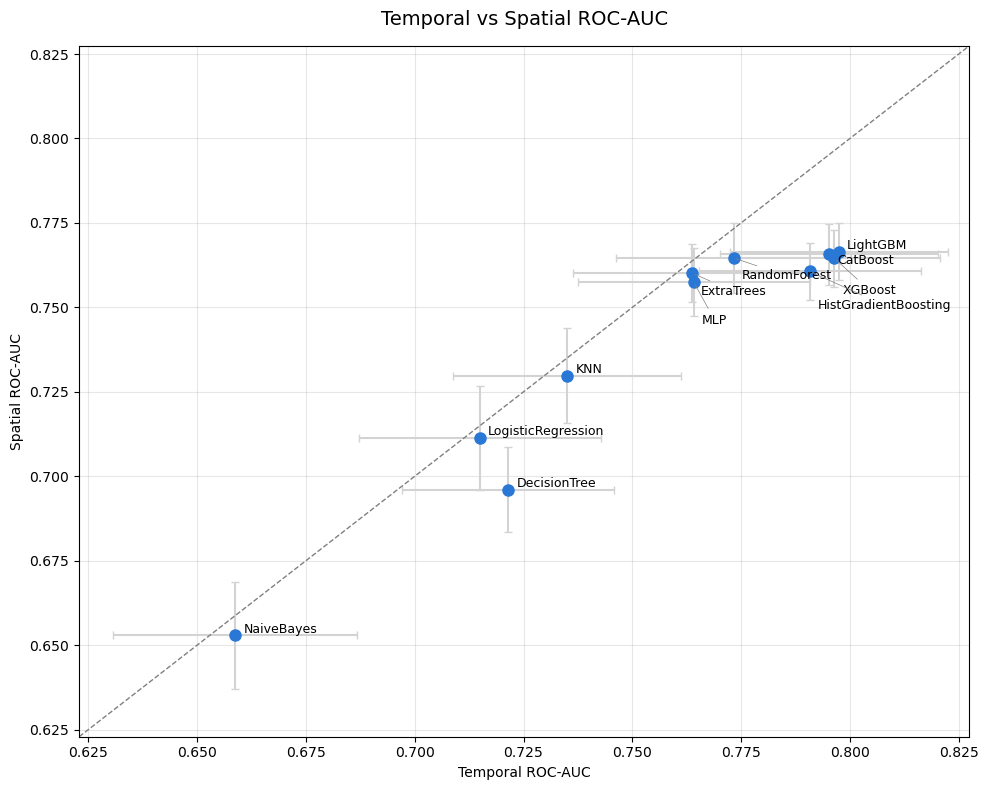

In [15]:
plot_df = summary.loc[MODELS_NO_BASELINE]

fig, ax = plt.subplots(figsize=(10, 8))

ax.errorbar(plot_df['temporal_auc'], plot_df['spatial_auc'],
            xerr=plot_df['temporal_std'], yerr=plot_df['spatial_std'],
            fmt='o', color=TEMPORAL_COLOR, ecolor='lightgray', markersize=8, capsize=3)

# Diagonal: same performance in both tests
limits = [plot_df[['temporal_auc', 'spatial_auc']].min().min() - 0.03, plot_df[['temporal_auc', 'spatial_auc']].max().max() + 0.03]
ax.plot(limits, limits, ls='--', color='gray', lw=1)

ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_xlabel("Temporal ROC-AUC")
ax.set_ylabel("Spatial ROC-AUC")
ax.set_title("Temporal vs Spatial ROC-AUC", fontsize=14, pad=15)
ax.grid(alpha=0.3)

plt.tight_layout()
label_points(ax, plot_df['temporal_auc'], plot_df['spatial_auc'], plot_df.index)
plt.show()

#### ROC Curves Per Family
The predictions of every year / fold are joined in a single curve. Only the best model of each family is drawn, models of the same family give almost identical curves.

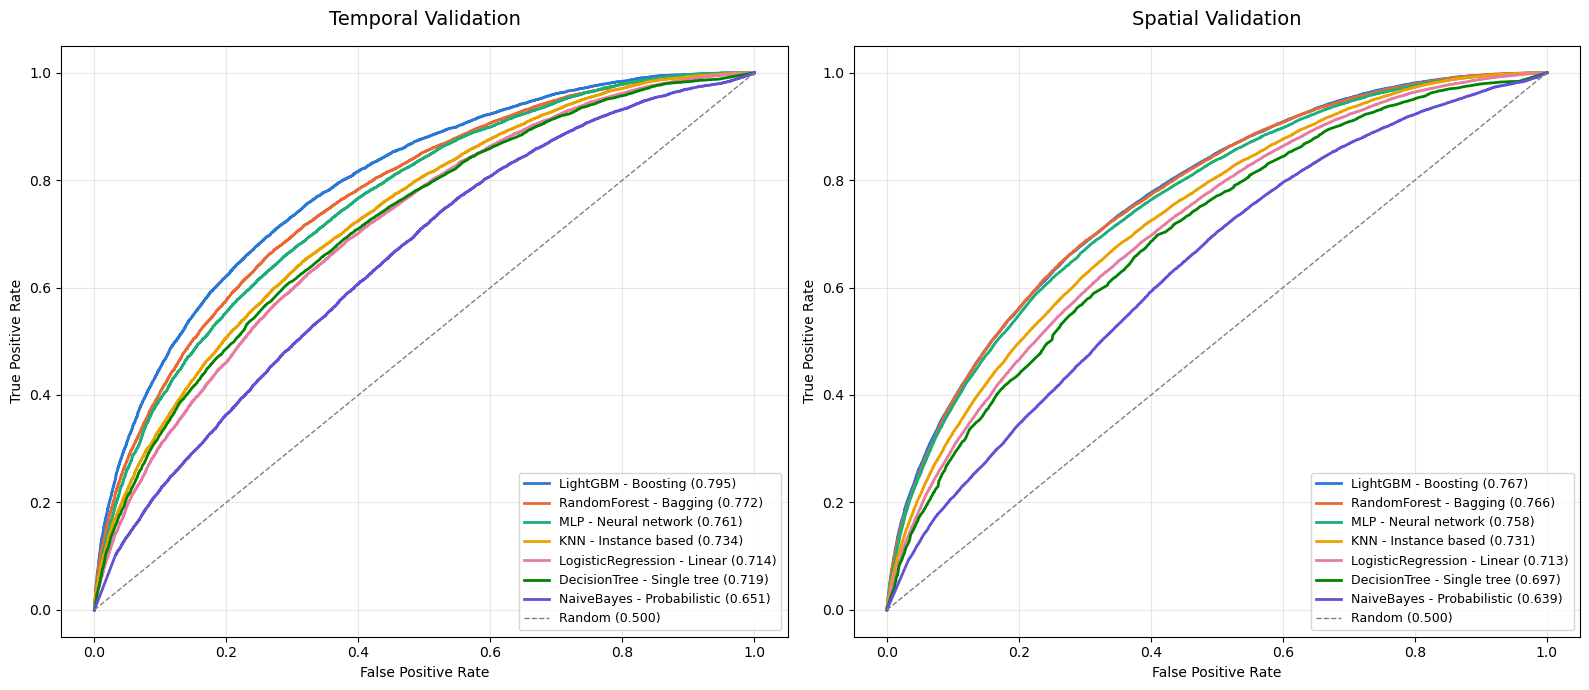

In [16]:
# Best model of each family, following the ranking of the summary
FAMILY_BEST = summary.loc[MODELS_NO_BASELINE].groupby(lambda m: MODEL_FAMILY[m], sort=False).head(1).index.tolist()
FAMILY_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, scheme in zip(axes, ['temporal', 'spatial']):
    for model, color in zip(FAMILY_BEST, FAMILY_COLORS):
        y_true, y_proba = predictions[(model, scheme)]
        fpr, tpr, _ = roc_curve(y_true, y_proba)
        ax.plot(fpr, tpr, color=color, lw=2, label=f"{model} - {MODEL_FAMILY[model]} ({roc_auc_score(y_true, y_proba):.3f})")

    ax.plot([0, 1], [0, 1], ls='--', color='gray', lw=1, label='Random (0.500)')

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{scheme.capitalize()} Validation", fontsize=14, pad=15)
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### All Metrics Overview
Color shows the position of each model inside its column (darker = better), the number is the real value of the metric. The baseline is left out so it doesn't flatten the color scale. F1 uses the 0.5 threshold, so models without class balancing (Naive Bayes, KNN, MLP) can be penalized there.

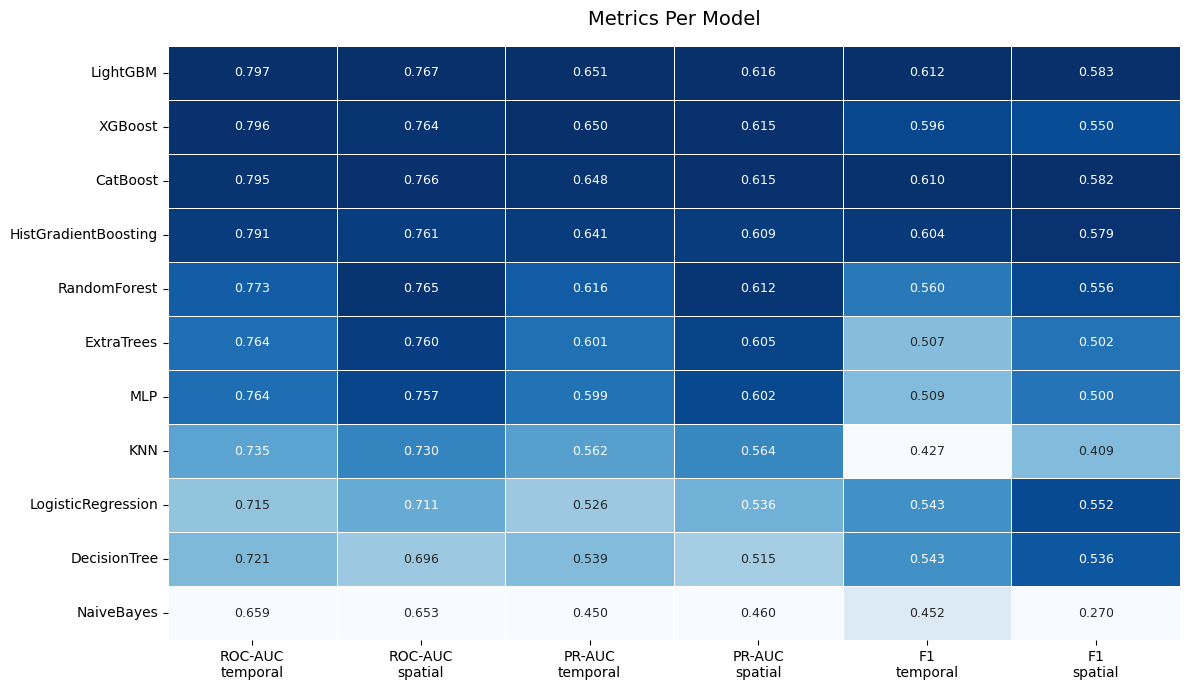

In [17]:
metrics_table = summary.loc[MODELS_NO_BASELINE, ['temporal_auc', 'spatial_auc', 'temporal_pr_auc', 'spatial_pr_auc', 'temporal_f1', 'spatial_f1']]
metrics_table.columns = ['ROC-AUC\ntemporal', 'ROC-AUC\nspatial', 'PR-AUC\ntemporal', 'PR-AUC\nspatial', 'F1\ntemporal', 'F1\nspatial']

# Each column scaled to [0, 1] so all the metrics share the same color scale
normalized = (metrics_table - metrics_table.min()) / (metrics_table.max() - metrics_table.min())

plt.figure(figsize=(12, 7))

sns.heatmap(normalized, annot=metrics_table, fmt=".3f", cmap="Blues", linewidths=0.5, cbar=False, annot_kws={"size": 9})

plt.xticks(rotation=0)
plt.ylabel("")
plt.title("Metrics Per Model", fontsize=14, pad=15)

plt.tight_layout()
plt.show()

#### Performance vs Training Time
Mean training time of a single fit (log scale). Useful to decide if the extra complexity of a model is worth it.

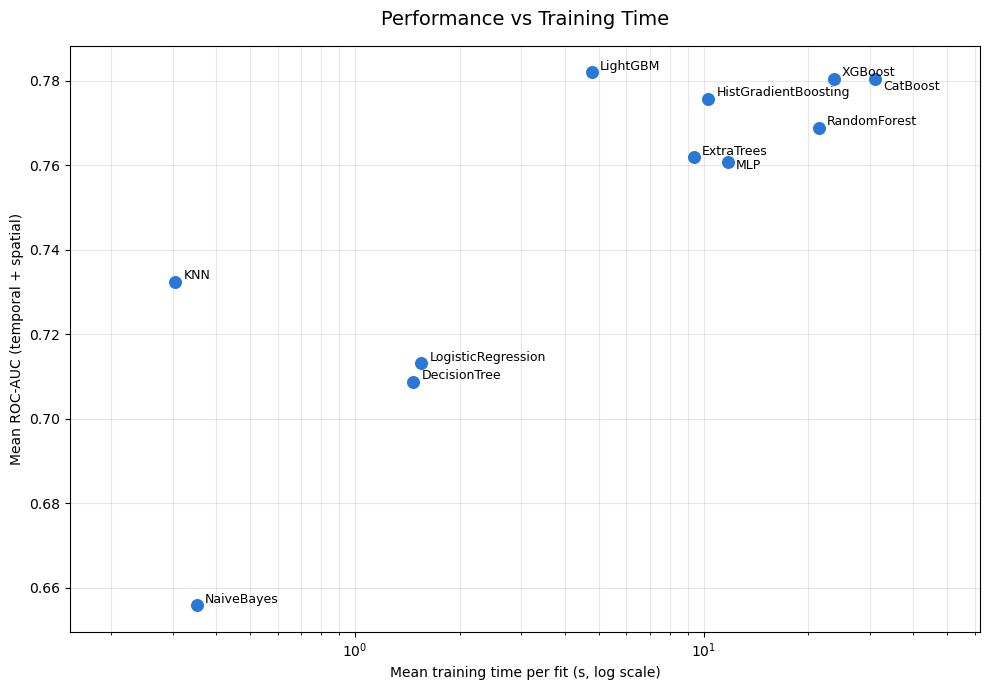

In [18]:
plot_df = summary.loc[MODELS_NO_BASELINE]
mean_auc = (plot_df['temporal_auc'] + plot_df['spatial_auc']) / 2

fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(plot_df['fit_time'], mean_auc, s=70, color=TEMPORAL_COLOR, zorder=3)

ax.set_xscale('log')
ax.margins(x=0.15) # Room for the labels of the slowest models
ax.set_xlabel("Mean training time per fit (s, log scale)")
ax.set_ylabel("Mean ROC-AUC (temporal + spatial)")
ax.set_title("Performance vs Training Time", fontsize=14, pad=15)
ax.grid(alpha=0.3, which='both')

plt.tight_layout()
label_points(ax, plot_df['fit_time'], mean_auc, plot_df.index)
plt.show()